# Recurrent Neural Networks

In this lab, we will introduce different ways of learning from sequential data.

As a recurring example, we will train neural networks to do language modelling, i.e. predict the next token in a sentence. In the context of natural language processing a token could be a character or a word, but mind you that the concepts introduced here apply to all kinds of sequential data, such as e.g. protein sequences, weather measurements, audio signals, or videos, just to name a few.

To really get a grasp of what is going on inside a recurrent neural network (RNN), we will carry out a substantial part of this exercise in Nanograd rather than PyTorch. 

We start off with a simple toy problem, build an RNN using Nanograd, train it, and see for ourselves that it really works. Once we're convinced, you will implement the Long Short-Term Memory (LSTM) cell, also in Nanograd. 

This is *not* simple but with the DenseLayer class we already have, it is doable. Having done it yourself will help you understand what happens under the hood of the PyTorch code we will use throughout the course.

To summarize, in this notebook we will show you:
* How to represent sequences of categorical variables
* How to build and train an RNN in Nanograd
* How to build and train an LSTM network in Nanograd
* How to build and train an LSTM network in PyTorch

## Representing tokens or text

In previous labs we mainly considered data $x \in \mathbb{R}^d$, where $d$ is the feature space dimension.
With time sequences our data can be represented as $x \in \mathbb{R}^{t \, \times \, d}$, where $t$ is the sequence length. 
This emphasises sequence dependence and that the samples along the sequence are not independent and identically distributed (i.i.d.).

With RNNs, we can model both many-to-one functions: $\mathbb{R}^{t \, \times \, d} \rightarrow \mathbb{R}^c$ and many-to-many functions: $\mathbb{R}^{t \, \times \, d} \rightarrow \mathbb{R}^{t \, \times \, c}$, where $c$ is the amount of classes/output dimensions.

There are several ways to represent sequences. With text, the challenge is how to represent a word as a feature vector in $d$ dimensions, as we are required to represent text with decimal numbers in order to apply neural networks to it.

In this exercise we will use a simple one-hot encoding but for categorical variables that can take on many values (e.g. words in the English language) this may be infeasible. For such scenarios, you can project the encodings into a smaller space by use of embeddings. If you want to learn more about tokens, encodings and embeddings than what is covered in this exercise, we highly recommend [this lecture](https://www.youtube.com/watch?v=kEMJRjEdNzM&list=PLoROMvodv4rOhcuXMZkNm7j3fVwBBY42z).

### One-hot encoding over vocabulary

One way to represent a fixed amount of words is by making a one-hot encoded vector, which consists of 0s in all cells with the exception of a single 1 in a cell used uniquely to identify each word.

| vocabulary    | one-hot encoded vector   |
| ------------- |--------------------------|
| Paris         | $= [1, 0, 0, \ldots, 0]$ |
| Rome          | $= [0, 1, 0, \ldots, 0]$ |
| Copenhagen    | $= [0, 0, 1, \ldots, 0]$ |

Representing a large vocabulary with one-hot encodings often becomes inefficient because of the size of each sparse vector.
To overcome this challenge it is common practice to truncate the vocabulary to contain the $k$ most used words and represent the rest with a special symbol, $\mathtt{UNK}$, to define unknown/unimportant words.
This often causes entities such as names to be represented with $\mathtt{UNK}$ because they are rare.

Consider the following text
> I love the corny jokes in Spielberg's new movie.

where an example result would be similar to
> I love the corny jokes in $\mathtt{UNK}$'s new movie.

## Generating a dataset

For this exercise we will create a simple dataset that we can learn from. We generate sequences of the form:

`a b EOS`,

`a a b b EOS`,

`a a a a a b b b b b EOS`

where `EOS` is a special character denoting the end of a sequence. The task is to predict the next token $t_n$, i.e. `a`, `b`, `EOS` or the unknown token `UNK` given a sequence of tokens $\{ t_{1}, t_{2}, \dots , t_{n-1}\}$, and we are to process sequences in a sequential manner. As such, the network will need to learn that e.g. 5 `b`s and an `EOS` token will follow 5 `a`s.

In [19]:
import numpy as np

# Set seed such that we always get the same dataset
# (this is a good idea in general)
np.random.seed(42)

def generate_dataset(num_sequences=2**5):
    """
    Generates a number of sequences as our dataset.
    
    Args:
     `num_sequences`: the number of sequences to be generated.
     
    Returns a list of sequences.
    """
    samples = []
    
    for _ in range(num_sequences): 
        num_tokens = np.random.randint(1, 4)
        sample = ['a'] * num_tokens + ['b'] * num_tokens + ['EOS']
        samples.append(sample)
        
    return samples


sequences = generate_dataset()

print('A single sample from the generated dataset:')
print(sequences[0])

A single sample from the generated dataset:
['a', 'a', 'a', 'b', 'b', 'b', 'EOS']


## Representing tokens as indices

To build a one-hot encoding, we need to assign each possible word in our vocabulary an index. We do that by creating two dictionaries: one that allows us to go from a given word to its corresponding index in our vocabulary, and one for the reverse direction. Let's call them `word_to_idx` and `idx_to_word`. The keyword `vocab_size` specifies the maximum size of our vocabulary. If we try to access a word that does not exist in our vocabulary, it is automatically replaced by the `UNK` token or its corresponding index.

## Exercise a) Sequence to dictionary function 

Complete the sequences_to_dicts function below. You will need to fill the word_to_idx and idx_to_word dictionaries so that we can go back and forth between the two representations.

In [20]:
from collections import defaultdict

def sequences_to_dicts(sequences):
    """
    Creates word_to_idx and idx_to_word dictionaries for a list of sequences.
    """
    # A bit of Python-magic to flatten a nested list
    flatten = lambda l: [item for sublist in l for item in sublist]
    
    # Flatten the dataset
    all_words = flatten(sequences)
    
    # Count number of word occurences
    word_count = defaultdict(int)
    for word in flatten(sequences):
        word_count[word] += 1

    # Sort by frequency
    word_count = sorted(list(word_count.items()), key=lambda l: -l[1])

    # Create a list of all unique words
    unique_words = [item[0] for item in word_count]
    
    # Add UNK token to list of words
    unique_words.append('UNK')

    # Count number of sequences and number of unique words
    num_sentences, vocab_size = len(sequences), len(unique_words)

    # Create dictionaries so that we can go from word to index and back
    # If a word is not in our vocabulary, we assign it to token 'UNK'
    word_to_idx = defaultdict(lambda: vocab_size-1)
    idx_to_word = defaultdict(lambda: 'UNK')

    # Fill dictionaries
    for idx, word in enumerate(unique_words):
        word_to_idx[word] = idx
        idx_to_word[idx] = word

    return word_to_idx, idx_to_word, num_sentences, vocab_size


word_to_idx, idx_to_word, num_sequences, vocab_size = sequences_to_dicts(sequences)

print(f'We have {num_sequences} sentences and {len(word_to_idx)} unique tokens in our dataset (including UNK).\n')
print('The index of \'b\' is', word_to_idx['b'])
print(f'The word corresponding to index 1 is \'{idx_to_word[1]}\'')

assert idx_to_word[word_to_idx['b']] == 'b', \
    'Consistency error: something went wrong in the conversion.'

We have 32 sentences and 4 unique tokens in our dataset (including UNK).

The index of 'b' is 1
The word corresponding to index 1 is 'b'


## Partitioning the dataset

To build our dataset, we need to create inputs and targets for each sequences and partition sentences it into training, validation and test sets. 80%, 10% and 10% is a common distribution, but mind you that this largely depends on the size of the dataset. Since we are doing next-word predictions, our target sequence is simply the input sequence shifted by one word.

We can use PyTorch's `Dataset` class to build a simple dataset where we can easily retrieve (inputs, targets) pairs for each of our sequences.

In [21]:
from torch.utils import data

class Dataset(data.Dataset):
    def __init__(self, inputs, targets):
        self.inputs = inputs
        self.targets = targets

    def __len__(self):
        # Return the size of the dataset
        return len(self.targets)

    def __getitem__(self, index):
        # Retrieve inputs and targets at the given index
        X = self.inputs[index]
        y = self.targets[index]

        return X, y

    
def create_datasets(sequences, dataset_class, p_train=0.8, p_val=0.1, p_test=0.1):
    # Define partition sizes
    num_train = int(len(sequences)*p_train)
    num_val = int(len(sequences)*p_val)
    num_test = int(len(sequences)*p_test)

    # Split sequences into partitions
    sequences_train = sequences[:num_train]
    sequences_val = sequences[num_train:num_train+num_val]
    sequences_test = sequences[-num_test:]

    def get_inputs_targets_from_sequences(sequences):
        # Define empty lists
        inputs, targets = [], []
        
        # Append inputs and targets s.t. both lists contain L-1 words of a sentence of length L
        # but targets are shifted right by one so that we can predict the next word
        for sequence in sequences:
            inputs.append(sequence[:-1])
            targets.append(sequence[1:])
            
        return inputs, targets

    # Get inputs and targets for each partition
    inputs_train, targets_train = get_inputs_targets_from_sequences(sequences_train)
    inputs_val, targets_val = get_inputs_targets_from_sequences(sequences_val)
    inputs_test, targets_test = get_inputs_targets_from_sequences(sequences_test)

    # Create datasets
    training_set = dataset_class(inputs_train, targets_train)
    validation_set = dataset_class(inputs_val, targets_val)
    test_set = dataset_class(inputs_test, targets_test)

    return training_set, validation_set, test_set
    

training_set, validation_set, test_set = create_datasets(sequences, Dataset)

print(f'We have {len(training_set)} samples in the training set.')
print(f'We have {len(validation_set)} samples in the validation set.')
print(f'We have {len(test_set)} samples in the test set.')

We have 25 samples in the training set.
We have 3 samples in the validation set.
We have 3 samples in the test set.


When working with more complex data than what we use in this exercise, creating a PyTorch `DataLoader` on top of the dataset can be beneficial. A data loader is basically a fancy generator/iterator that we can use to abstract away all of the data handling and pre-processing + it's super useful for processing batches of data as well! Data loaders will come in handy later when you start to work on your projects, so be sure to check them out!

For more information on how to use datasets and data loaders in PyTorch, [consult the official guide](https://pytorch.org/tutorials/beginner/data_loading_tutorial.html).

## One-hot encodings

We now create a simple function that returns the one-hot encoded representation of a given index of a word in our vocabulary. Notice that the shape of the one-hot encoding is equal to the entire vocabulary (which can be huge!). Additionally, we define a function to automatically one-hot encode a sentence.

In [22]:
def one_hot_encode(idx, vocab_size):
    """
    One-hot encodes a single word given its index and the size of the vocabulary.
    
    Args:
     `idx`: the index of the given word
     `vocab_size`: the size of the vocabulary
    
    Returns a 1-D numpy array of length `vocab_size`.
    """
    # Initialize the encoded array
    one_hot = np.array([np.zeros(vocab_size)])
    
    # Set the appropriate element to one
    one_hot[0][idx] = 1.0
    return one_hot


def one_hot_encode_sequence(sequence, vocab_size):
    """
    One-hot encodes a sequence of words given a fixed vocabulary size.
    
    Args:
     `sentence`: a list of words to encode
     `vocab_size`: the size of the vocabulary
     
    Returns a 3-D numpy array of shape (num words, vocab size, 1).
    """
    # Encode each word in the sentence
    encoding = np.array([one_hot_encode(word_to_idx[word], vocab_size) for word in sequence])

    # Reshape encoding s.t. it has shape (num words, vocab size, 1)
    encoding = encoding.reshape(encoding.shape[0], encoding.shape[2], 1)
    return encoding

test_word = one_hot_encode(word_to_idx['a'], vocab_size)
print(f'Our one-hot encoding of \'a\' has shape {test_word.shape}.')

test_sentence = one_hot_encode_sequence(['a', 'b'], vocab_size)
print(f'Our one-hot encoding of \'a b\' has shape {test_sentence.shape}.')

print(test_word)
print(test_sentence)

Our one-hot encoding of 'a' has shape (1, 4).
Our one-hot encoding of 'a b' has shape (2, 4, 1).
[[1. 0. 0. 0.]]
[[[1.]
  [0.]
  [0.]
  [0.]]

 [[0.]
  [1.]
  [0.]
  [0.]]]


In [23]:
encoded_training_set_x = []
encoded_training_set_y = []
encoded_validation_set_x = []
encoded_validation_set_y = []
encoded_test_set_x = []
encoded_test_set_y = []

for n in range(len(training_set)):
  encoded_training_set_x.append(one_hot_encode_sequence(training_set[n][0], vocab_size))
  encoded_training_set_y.append(one_hot_encode_sequence(training_set[n][1], vocab_size))
for n in range(len(validation_set)):
  encoded_validation_set_x.append(one_hot_encode_sequence(validation_set[n][0], vocab_size))
  encoded_validation_set_y.append(one_hot_encode_sequence(validation_set[n][1], vocab_size))
for n in range(len(test_set)):
  encoded_test_set_x.append(one_hot_encode_sequence(test_set[n][0], vocab_size))
  encoded_test_set_y.append(one_hot_encode_sequence(test_set[n][1], vocab_size))

Great! Now that we have our one-hot encodings in place, we can move on to the RNNs!

# Introduction to Recurrent Neural Networks (RNN)

Reading material: [blog post](http://karpathy.github.io/2015/05/21/rnn-effectiveness/) and (optionally) [this lecture](https://www.youtube.com/watch?v=iWea12EAu6U&list=PLoROMvodv4rOhcuXMZkNm7j3fVwBBY42z).

___

A recurrent neural network (RNN) is a type of neural network that has been succesful in modelling sequential data, e.g. language, speech, protein sequences, etc.

A RNN performs its computations in a cyclic manner, where the same computation is applied to every sample of a given sequence.
The idea is that the network should be able to use the previous computations as some form of memory and apply this to future computations.
An image may best explain how this is to be understood,

![rnn-unroll image](https://github.com/DeepLearningDTU/02456-2025/blob/master/static_files/rnn-unfold.png?raw=1)


where it the network contains the following elements:

- $x$ is the input sequence of samples, 
- $U$ is a weight matrix applied to the given input sample,
- $V$ is a weight matrix used for the recurrent computation in order to pass memory along the sequence,
- $W$ is a weight matrix used to compute the output of the every timestep (given that every timestep requires an output),
- $h$ is the hidden state (the network's memory) for a given time step, and
- $o$ is the resulting output.

When the network is unrolled as shown, it is easier to refer to a timestep, $t$.
We have the following computations through the network:

- $h_t = f(U\,{x_t} + V\,{h_{t-1}})$, where $f$ is a non-linear activation function, e.g. $\mathrm{tanh}$.
- $o_t = W\,{h_t}$

When we are doing language modelling using a cross-entropy loss, we additionally apply the softmax function to the output $o_{t}$:

- $\hat{y}_t = \mathrm{softmax}(o_{t})$


### Backpropagation through time

We define a loss function

- $E = \sum_t E_t  = \sum_t E_t(y_t ,\hat{y}_t ) \ , $

where $E_t(y_t ,\hat{y}_t )$ is the cross-entropy function.

Backpropagation through time amounts to computing the gradients of the loss using the same type of clever bookkeeping we applied to the feed-forward network in week 1. This you will do in Exercise D.

# Introduction to the Long Short-Term Memory (LSTM) Cell

Reading material: [Christopher Olah's walk-through](http://colah.github.io/posts/2015-08-Understanding-LSTMs/).

___


A vanilla RNN suffers from [the vanishing gradients problem](http://neuralnetworksanddeeplearning.com/chap5.html#the_vanishing_gradient_problem) which gives challenges in saving memory over longer sequences. To combat these issues the gated hidden units were created. The two most prominent gated hidden units are the Long Short-Term Memory (LSTM) cell and the Gated Recurrent Unit (GRU), both of which have shown increased performance in saving and reusing memory in later timesteps. In this exercise, we will focus on LSTM but you would easily be able to go ahead and implement the GRU as well based on the principles that you learn here.

Below is a figure of the LSTM cell:

![lstm](https://i.imgur.com/3VkmUCe.png)
Source: https://arxiv.org/abs/1412.7828


The LSTM cell contains three gates, input, forget, output gates and a memory cell.
The output of the LSTM unit is computed with the following functions, where $\sigma = \mathrm{sigmoid}$.
We have input gate $i$, forget gate $f$, and output gate $o$ defines as

- $i = \sigma ( W^i [h_{t-1}, x_t])$

- $f = \sigma ( W^f [h_{t-1},x_t])$

- $o = \sigma ( W^o [h_{t-1},x_t])$

where $W^i, W^f, W^o$ are weight matrices applied to a concatenated $h_{t-1}$ (hidden state vector) and $x_t$ (input vector)  for each respective gate.

$h_{t-1}$, from the previous time step along with the current input $x_t$ are used to compute the a candidate $g$

- $g = \mathrm{tanh}( W^g [h_{t-1}, x_t])$

The value of the cell's memory, $c_t$, is updated as

- $c_t = c_{t-1} \circ f + g \circ i$

where $c_{t-1}$ is the previous memory, and $\circ$ refers to element-wise multiplication (hint: element-wise multiplication is computed with the `*` operator in numpy).

The output, $h_t$, is computed as

- $h_t = \mathrm{tanh}(c_t) \circ o$

and it is used for both the timestep's output and the next timestep, whereas $c_t$ is exclusively sent to the next timestep.
This makes $c_t$ a memory feature, and is not used directly to compute the output of the timestep.

Here is a bit of code to test it out:

## PyTorch implementation of the LSTM

Now that we know how the LSTM cell works, let's see how easy it is to use in PyTorch!

Definition of our LSTM network. We define a LSTM layer using the [nn.LSTM](https://pytorch.org/docs/stable/nn.html#lstm) class. The LSTM layer takes as argument the size of the input and the size of the hidden state like in our Nanograd implementation.

In [24]:
#even if batch changes that doesn't change here
#only embedding can be added here 

import torch
import torch.nn as nn
import torch.nn.functional as F

class MyRecurrentNet(nn.Module):
    def __init__(self):
        super(MyRecurrentNet, self).__init__()
        
        # Recurrent layer
        # YOUR CODE HERE!
        self.lstm = nn.LSTM(input_size=vocab_size, hidden_size=50)
        
        # Output layer
        self.l_out = nn.Linear(in_features=50,
                            out_features=vocab_size,
                            bias=False)
        
    def forward(self, x):
        # RNN returns output and last hidden state
        x, (h, c) = self.lstm(x)
        
        # Flatten output for feed-forward layer
        x = x.view(-1, self.lstm.hidden_size)
        
        # Output layer
        x = self.l_out(x)
        
        return x

net = MyRecurrentNet()
print(net)

MyRecurrentNet(
  (lstm): LSTM(4, 50)
  (l_out): Linear(in_features=50, out_features=4, bias=False)
)


## Exercise j) Train in PyTorch

Define an LSTM for our recurrent neural network `MyRecurrentNet` above. A single LSTM layer is sufficient. What should the input size and hidden size be? Hint: use the PyTorch documentation.

It's time for us to train our network. In the section below, you will get to put your deep learning skills to use and create your own training loop. You may want to consult previous exercises if you cannot recall how to define the training loop.

In [25]:
# lets redefine the one_hot_encode() and one_hot_encode_sequence() functions
# to work now with torch.Tensor variables instead of Var.
def one_hot_encode(idx, vocab_size):
    """
    One-hot encodes a single word given its index and the size of the vocabulary.
    
    Args:
     `idx`: the index of the given word
     `vocab_size`: the size of the vocabulary
    
    Returns a 1-D numpy array of length `vocab_size`.
    """
    # Initialize the encoded array
    one_hot = np.array([np.zeros(vocab_size)])
    
    # Set the appropriate element to one
    one_hot[0][idx] = 1.0
    return one_hot


def one_hot_encode_sequence(sequence, vocab_size):
    """
    One-hot encodes a sequence of words given a fixed vocabulary size.
    
    Args:
     `sentence`: a list of words to encode
     `vocab_size`: the size of the vocabulary
     
    Returns a 3-D torch.Tensor of shape (num words, vocab size, 1).
    """
    # Encode each word in the sentence
    encoding = np.array([one_hot_encode(word_to_idx[word], vocab_size) for word in sequence])

    # Reshape encoding s.t. it has shape (num words, vocab size, 1)
    encoding = encoding.reshape(encoding.shape[0], encoding.shape[2], 1)
    return torch.Tensor(encoding)

# lets test it
test_word = one_hot_encode(word_to_idx['a'], vocab_size)
print(f'Our one-hot encoding of \'a\' has shape {test_word.shape}.')

test_sentence = one_hot_encode_sequence(['a', 'b'], vocab_size)
print(f'Our one-hot encoding of \'a b\' has shape {test_sentence.shape}.')

print(test_word)
print(test_sentence)

Our one-hot encoding of 'a' has shape (1, 4).
Our one-hot encoding of 'a b' has shape torch.Size([2, 4, 1]).
[[1. 0. 0. 0.]]
tensor([[[1.],
         [0.],
         [0.],
         [0.]],

        [[0.],
         [1.],
         [0.],
         [0.]]])


Epoch 0, training loss: 1.3486251974105834, validation loss: 1.3829975525538127
Epoch 10, training loss: 0.6789860916137695, validation loss: 0.7927415569623312
Epoch 20, training loss: 0.41678563237190247, validation loss: 0.4849004050095876
Epoch 30, training loss: 0.3443935418128967, validation loss: 0.3658600449562073
Epoch 40, training loss: 0.32590882301330565, validation loss: 0.33068955938021344
Epoch 50, training loss: 0.31902514457702635, validation loss: 0.31490179896354675
Epoch 60, training loss: 0.31582667350769045, validation loss: 0.30814236402511597
Epoch 70, training loss: 0.3140042245388031, validation loss: 0.30522671341896057
Epoch 80, training loss: 0.3128139054775238, validation loss: 0.303794264793396
Epoch 90, training loss: 0.31196468234062197, validation loss: 0.30297282338142395
Epoch 100, training loss: 0.3113201129436493, validation loss: 0.30244089166323346
Epoch 110, training loss: 0.31080729126930234, validation loss: 0.30206666390101117
Epoch 120, trai

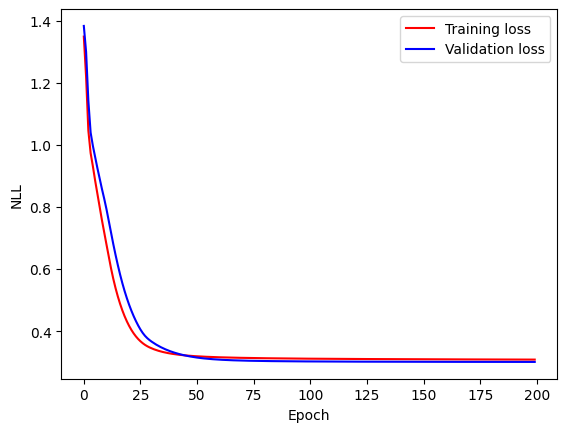

In [26]:
# Hyper-parameters
num_epochs = 200 # how many times full pass over our training set 

# Initialize a new network
net = MyRecurrentNet()

# Define a loss function and optimizer for this problem
# YOUR CODE HERE!
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(net.parameters(), lr=1e-3)

# Track loss
training_loss, validation_loss = [], []

# For each epoch
for i in range(num_epochs):
    
    # Track loss
    epoch_training_loss = 0
    epoch_validation_loss = 0
    
    net.eval()
        
    # For each sentence in validation set
    for inputs, targets in validation_set:
        
        # One-hot encode input and target sequence
        inputs_one_hot = one_hot_encode_sequence(inputs, vocab_size)
        targets_idx = [word_to_idx[word] for word in targets]
        
        # Convert input to tensor
        inputs_one_hot = torch.Tensor(inputs_one_hot)
        inputs_one_hot = inputs_one_hot.permute(0, 2, 1)
        
        # Convert target to tensor
        targets_idx = torch.LongTensor(targets_idx)
        
        # Forward pass
        # YOUR CODE HERE!
        outputs = net(inputs_one_hot)
        
        # Compute loss
        # YOUR CODE HERE!
        loss = criterion(outputs, targets_idx)
        
        # Update loss
        epoch_validation_loss += loss.detach().numpy()
    
    net.train()
    
    # For each sentence in training set
    for inputs, targets in training_set:
        
        # One-hot encode input and target sequence
        inputs_one_hot = one_hot_encode_sequence(inputs, vocab_size)
        targets_idx = [word_to_idx[word] for word in targets]
        
        # Convert input to tensor
        inputs_one_hot = torch.Tensor(inputs_one_hot)
        inputs_one_hot = inputs_one_hot.permute(0, 2, 1)
        
        # Convert target to tensor
        targets_idx = torch.LongTensor(targets_idx)
        
        # Forward pass
        # YOUR CODE HERE!
        outputs = net(inputs_one_hot)
        
        # Compute loss
        # YOUR CODE HERE!
        loss = criterion(outputs, targets_idx)
        
        # Backward pass
        # YOUR CODE HERE!
        # zero grad, backward, step...
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        # Update loss
        epoch_training_loss += loss.detach().numpy()
        
    # Save loss for plot
    training_loss.append(epoch_training_loss/len(training_set))
    validation_loss.append(epoch_validation_loss/len(validation_set))

    # Print loss every 10 epochs
    if i % 10 == 0:
        print(f'Epoch {i}, training loss: {training_loss[-1]}, validation loss: {validation_loss[-1]}')

        
# Get first sentence in test set
inputs, targets = test_set[1]

# One-hot encode input and target sequence
inputs_one_hot = one_hot_encode_sequence(inputs, vocab_size)
targets_idx = [word_to_idx[word] for word in targets]

# Convert input to tensor
inputs_one_hot = torch.Tensor(inputs_one_hot)
inputs_one_hot = inputs_one_hot.permute(0, 2, 1)

# Convert target to tensor
targets_idx = torch.LongTensor(targets_idx)

# Forward pass
outputs = net.forward(inputs_one_hot).data.numpy()

print('\nInput sequence:')
print(inputs)

print('\nTarget sequence:')
print(targets)

print('\nPredicted sequence:')
print([idx_to_word[np.argmax(output)] for output in outputs])

# Plot training and validation loss
import matplotlib.pyplot as plt
epoch = np.arange(len(training_loss))
plt.figure()
plt.plot(epoch, training_loss, 'r', label='Training loss',)
plt.plot(epoch, validation_loss, 'b', label='Validation loss')
plt.legend()
plt.xlabel('Epoch'), plt.ylabel('NLL')
plt.show()

# Exercise k) Compare PyTorch and Nanograd implementations

Compare the two implementations (in terms of predictive performance, training speed, etc.). Are they similar? How do they differ?


Try to play around with the choice of hyper-parameters, optimizer, and hidden dimensions. How much can you improve the negative log-likelihood by these simple changes?

## Exercise l) Other RNN cells (optional)

Aside from the LSTM cell, various other RNN cells exist. The gated recurrent unit (GRU) is a variation of the LSTM cell that uses less gating mechanisms. Try to look it up in the [PyTorch documentation](https://pytorch.org/docs/stable/nn.html#gru) and switch out the LSTM cell in the code above. What do you notice in terms of performance and convergence speed?

## Exercise m) More complex tasks (optional)

Go back and generate a more complex patterned dataset to learn from. Do you see any significant differences between a vanilla RNN and LSTM (implemented in e.g. PyTorch) when you increase the difficulty of the task?

# It works, now what?

In this notebook you have learned how to use embeddings, recurrent neural networks, and the LSTM cell in particular.

As we have already seen, RNNs are excellent for sequential data such as language. But what do we do if we're modelling data with strong dependency in both directions? Like in many things deep learning, we can build powerful models by stacking layers on top of each other; *bi-directional* RNNs consist of two LSTM cells, one for each direction. A sequence is first fed into the forward LSTM cell and the reversed sequence is then used as input to the backward LSTM cell together with the last hidden state from the forward LSTM cell. Follow [this link](https://pdfs.semanticscholar.org/4b80/89bc9b49f84de43acc2eb8900035f7d492b2.pdf) for the original paper from 1997(!).

For even deeper representations, multiple layers of both uni-directional and bi-directional RNNs can be stacked ontop of each other, just like feed-forward and convolutional layers. For more information on this, check out the [LSTM PyTorch documentation](https://pytorch.org/docs/stable/nn.html#lstm). Next week we will also explore ways to combine RNNs with other types of layers for even more expressive function approximators.